# Problema de inventario.

## Descripción del Problema.

Considere un producto en una tienda. Debemos construir una estrategia para maximizar las ganancias.

## Descripción del Modelo.

Para construir nuestro modelo. Vamos a definir las variables elementales.

* $x_t$ es la cantidad del producto disponible en la etapa $t$.
* $\xi_t$ es la cantidad de producto demandada en la etapa $t$.
* $a_t$ es la cantidad de producto pedida en la etapa $t$.

Notemos que dada la cantidad inicial $x_0$ en la etapa cero. En la siguiente etapa, después de pedir $a_0$ productos, se observa una demanda $\xi_1$. Entonces la cantidad de producto en la siguiente etapa sería 
$$
    x_1 = x_0 + a_0 - \xi_1.
$$
Sin embargo, puede darse el caso que $\xi_1>x_0+a_0$, entonces nos quedaremos con la parte positiva. En general, la cantidad de producto en la etapa $t + 1$ esta dado por 
$$
    x_{t+1} = (x_t + a_t - \xi_{t+1})^{+},(\cdot)^{+}=\max(\cdot, 0)
$$

In [465]:
import numpy as np
from neuralnetworks.nn import sigmoid

def state(x, a, e):
    y = np.max([x + a - e, 0])
    return y

### Estados y Acciones

Viendo el problema, vemos que $x_t\in\mathbb{N}\cup\{0\}$ mientras que $a_t\in [0, M-x_t]$, donde $M$ es la capacidad máxima del espacio.

### Función de Recompensa

A lo largo de la libreta iremos revisando diferentes funciones de ganancia en función de los aditamientos que vayamos definiendo.

#### Ganancia simplificada.

La ganancia simplificada consiste en calcular ganancia comparando la ganancia bruta menos los costos. Sea $V$ el precio de venta y $C$ el costo de solicitar el producto, entonces 

$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t, R_0 = 0
$$

In [466]:
def simple_reward(x, a, e, v, c):
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    return reward


#### Ganancia sincera.

Definimos la ganancia sincera la ganancia simplificada pero agregando una penalización si la demanda llega a ser mayor al producto disponible. En general, podemos definirla con una penalización constante $\eta$
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta I_{\xi_{t+1}>x_t+a_t}.
$$

Pero, en caso de conocer la información, puede considérese proporcional al producto no vendido por carencia
$$
    R_{t+1} = V \min\{\xi_{t+1}, x_t+a_t\} - C a_t - \eta \max\{\xi_{t+1}-x_t-a_t, 0\}.
$$


In [467]:
def pure_reward(x,a,e,v,c,eta):
    # No observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = 1 if e > x + a else 0
    return reward - eta * pen


def pure_reward_obs(x, a, e, v, c, eta):
    # observable
    brute = v * np.min([x+a, e])
    cost = c * a
    reward = brute - cost
    pen = eta * np.max([e - x - a, 0])
    return reward - pen


### Demanda

Por lo general la demanda es desconocida. Pero para esta libreta estara dada


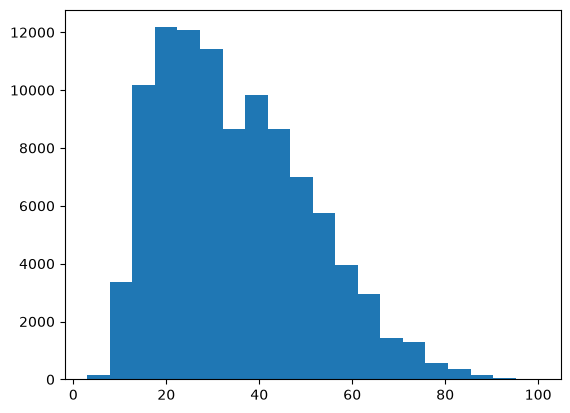

In [468]:
import matplotlib.pyplot as plt

np.random.seed(100)

def demand():
    y = np.random.poisson(lam=10) + np.random.randint(1,10) * np.random.binomial(10, 0.5)
    return y

demand_sample = [demand() for _ in range(100_000)]

fig, ax = plt.subplots()
ax.hist(demand_sample, bins=20)
plt.show()


In [469]:
MAX_CAP = 100
PRECIO_VENTA = 20
COSTO = 5
ETA = 100

## Simulaciones.
### Dinamica
Con el modelo terminado procedemos a poner pruebas.

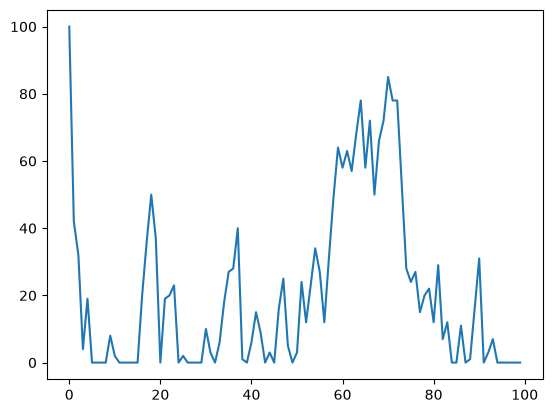

In [470]:
def simulate(x0, days, policy):
    history = []
    x, e_prev = x0, demand()
    for _ in range(days):
        a = np.clip(policy(x, e_prev), 0, MAX_CAP - x)
        e = demand()
        history.append((x, a, e))
        e_prev = e
        x = state(x, a, e)
    return history

test = simulate(100, 100, lambda x, e: 30)

xt = [u[0] for u in test]
plt.plot(xt)
plt.show()

### Recompensa

Luego, calculamos la recompensa por etapa y la recompensa final.

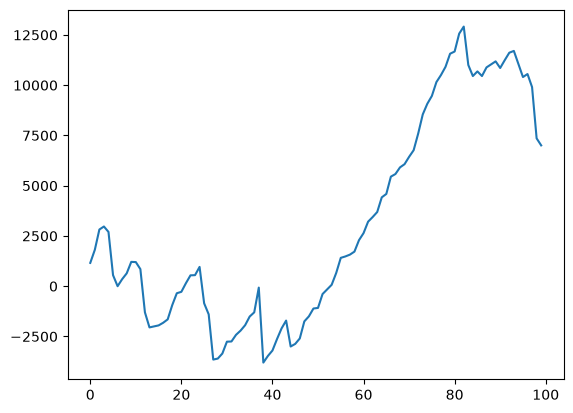

In [471]:
values = np.array([
    pure_reward_obs(item[0], item[1], item[2], PRECIO_VENTA, COSTO, ETA)
    for item in test
])
plt.plot(values.cumsum())
plt.show()

## Uso de Red Neuronal.

Ahora, vamos a construir la red Neuronal que pretende resolver este problema. Notemos que ahora $\mathfrak{m}(\cdot, \Theta):\mathbb{R}^2\to\mathbb{R}$. Si la capa tiene $N$ neuronas, entonces 

$$
    \mathfrak{m}(\cdot;\Theta) = \sum_{i=1}^{N}c^n\sigma(\mathbf{w}^n\cdot\mathbf{x} + b^n)

$$


In [472]:
def model(x: np.array, theta, act=sigmoid):
    assert x.shape[1] == 1, "Revisa la estructura"
    C = theta[:, 0].reshape((theta.shape[0],1))
    W = theta[:,1:(theta.shape[1]-1)]
    B = theta[:,-1].reshape((theta.shape[0],1))
    wx = np.dot(W, x)
    wxb = wx + B
    actx = act(wxb)
    y = C * actx
    return y.sum()

In [473]:
def svec(x, e):
    return np.array([[x],[e]])


def loss(Theta, days=100, x0=MAX_CAP):
    np.random.seed(7)
    hist = simulate(x0, days, lambda x, e: model(svec(x, e), Theta))
    total = sum(pure_reward_obs(x, a, e, PRECIO_VENTA, COSTO, ETA)
                for x, a, e in hist)
    return -total / days


def partial(func, k, var, tol = 10 ** (-5)):
    vh = var.copy()
    vh = vh.flatten()
    vh[k] += tol
    varh = vh.reshape(var.shape)
    dy = tol ** (-1) * (func(varh) - func(var))
    return dy


def gradient(func, Theta):
    lv = Theta.flatten()
    grad = np.array([partial(func, i, Theta) for i in range(len(lv))])
    grad = grad.reshape(Theta.shape)
    return grad

In [ ]:
NEURONS = 10
lr = 0.01
Theta = np.ones((NEURONS, 1 + 2 + 1))

for it in range(10):
    Theta = Theta - lr * gradient(loss, Theta)
    print(it, loss(Theta))

hist_nn = simulate(100, 100, lambda x, e: model(svec(x, e), Theta))
plt.plot([u[0] for u in hist_nn])
plt.show()